# Занятие 07. Внутри модели: что объясняет устройство модели? — демо и конспект

Перед каждым фрагментом кода есть:

- **Блок «Теория»** — что делает метод, формулы и пример;
- **Как устроен код** — тот же код на псевдоязыке;
- **В чём измеряется** — единицы того, что вывел код;
- **На что обращать внимание** — нюансы работы и границы метода, каждый с примером на этих данных.

**Рамка — та же, что на занятии 06:** единица объяснения, процесс (градиент или вмешательство), baseline, цель. На занятии 06 мы смотрели на модель как на функцию входа. Сегодня объяснение опирается на то, как модель устроена:

| Архитектура | Что хранит | Метод | Единица | Процесс | Цель |
|---|---|---|---|---|---|
| свёрточная сеть | карты признаков | Grad-CAM | клетка 7×7 | градиент по активациям | логит класса |
| трансформер | веса внимания | attention rollout | токен, патч | произведение матриц внимания | нет |
| графовая сеть | рёбра, сообщения | GNNExplainer | ребро | оптимизация маски | log p класса узла |
| мультимодальная | общее пространство | удаление слова | слово, патч | удаление, замена | косинус, p среди подписей |

Это не механистическая интерпретируемость: мы не разбираем, что делает каждый нейрон, а используем устройство модели, чтобы объяснить ответ.

> В ДЗ-2 модели и данные другие. Методы, которые ДЗ-2 просит реализовать самим, здесь даны через `captum` или только теорией.

## Библиотеки

| Библиотека | Зачем здесь |
|---|---|
| `torchvision` | ResNet-34 с весами ImageNet |
| `captum` | Grad-CAM (`LayerGradCam`), окклюзия |
| `transformers` | ViT-tiny для картинок, CLIP |
| `networkx` | граф Tree-Cycles |
| `scikit-image` | тестовые картинки |

In [1]:
import warnings, os; warnings.filterwarnings("ignore"); os.environ["TQDM_DISABLE"] = "1"
import numpy as np, matplotlib.pyplot as plt, torch, torch.nn as nn, torch.nn.functional as F, torchvision, networkx as nx
from PIL import Image
from skimage import data
from scipy.stats import spearmanr, pearsonr
from torchvision.transforms import GaussianBlur
from captum.attr import LayerGradCam, LayerAttribution, Occlusion
import transformers; transformers.logging.set_verbosity_error(); transformers.logging.disable_progress_bar()
from transformers import ViTForImageClassification, ViTImageProcessor, CLIPModel, CLIPProcessor
plt.rcParams["figure.dpi"] = 110
torch.manual_seed(0); np.random.seed(0)

W = torchvision.models.ResNet34_Weights.IMAGENET1K_V1
net = torchvision.models.resnet34(weights=W).eval()
for p in net.parameters(): p.requires_grad_(False)
tf = W.transforms(); CATS = W.meta["categories"]
MEAN = torch.tensor([0.485, 0.456, 0.406])[:, None, None]; STD = torch.tensor([0.229, 0.224, 0.225])[:, None, None]
def show(t): return (t * STD + MEAN).permute(1, 2, 0).clamp(0, 1).numpy()
def logits(x):
    with torch.no_grad(): return net(x)

XC = tf(Image.fromarray(data.chelsea()))[None]                       # кошка из skimage
cC = int(logits(XC)[0].argmax())
print("ResNet-34, топ-3:", [(CATS[int(i)], round(float(v), 3)) for v, i in zip(*logits(XC).softmax(-1)[0].topk(3))])

ResNet-34, топ-3: [('tiger cat', 0.643), ('tabby', 0.18), ('Egyptian cat', 0.167)]


---
# Часть 1. Свёрточная сеть: Grad-CAM

## 1.1. От CAM к Grad-CAM

### Блок «Теория»

**CAM** (Zhou et al., 2016; занятие 05). У ResNet после последнего свёрточного блока стоят global average pooling (GAP) и один линейный слой. Значит, логит класса $c$ раскладывается по клеткам карты признаков $A_k$ ($k$ — канал, $7\times7$ клеток):
$$f_c = \frac{1}{HW}\sum_{h,w}\sum_k w^c_k A_k(h,w) + b_c, \qquad \mathrm{CAM}^c = \sum_k w^c_k A_k.$$

**Grad-CAM** (Selvaraju et al., 2017) заменяет веса головы $w^c_k$ на усреднённые градиенты — и поэтому работает с любой свёрточной сетью и любым слоем:
$$\alpha^c_k = \frac{1}{HW}\sum_{h,w}\frac{\partial f_c}{\partial A_k(h,w)}, \qquad L^c = \mathrm{ReLU}\Big(\sum_k \alpha^c_k A_k\Big).$$

На ResNet при GAP $\partial f_c / \partial A_k(h,w) = w^c_k / HW$, поэтому без ReLU $\mathrm{CAM} = HW \cdot L^c$, то есть $49 \cdot L^c$. Grad-CAM — обобщение CAM.

По рамке: единица — клетка карты признаков, процесс — градиент по активациям, baseline нет, цель — логит класса.

**Пример.** Модель сказала «tiger cat». Grad-CAM подсвечивает, какие клетки последнего слоя «голосуют» за этот класс — полосы на лбу, глаза.

### Как устроен код
```
признаки A ← все слои ResNet до avgpool                # [512, 7, 7]
CAM ← Σ_k w_fc[c, k] · A_k
GradCAM ← captum.LayerGradCam(net, net.layer4), без ReLU
сравнить: корреляция, отношение CAM / GradCAM, mean(CAM) + b против логита
```

класс: tiger cat
Pearson(CAM, Grad-CAM) = 1.0000;  CAM / Grad-CAM = 49.00  (HW = 49)
mean(CAM) + b = 15.547;  логит = 15.547


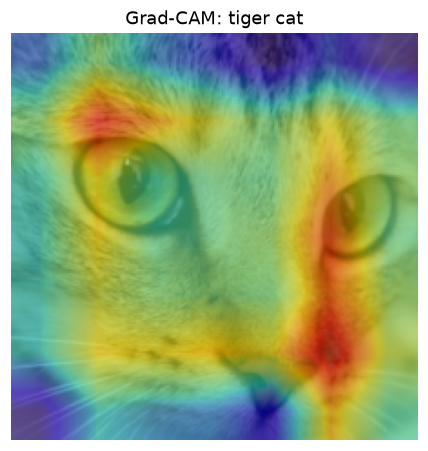

In [2]:
features = nn.Sequential(*list(net.children())[:-2])                 # всё до avgpool и fc
with torch.no_grad(): A = features(XC)[0]                             # [512, 7, 7]
CAM = torch.einsum("k,khw->hw", net.fc.weight[cC], A)
gc = LayerGradCam(net, net.layer4)
GC = gc.attribute(XC.clone().requires_grad_(True), target=cC, relu_attributions=False)[0, 0].detach()
print(f"класс: {CATS[cC]}")
print(f"Pearson(CAM, Grad-CAM) = {pearsonr(CAM.ravel(), GC.ravel())[0]:.4f};  CAM / Grad-CAM = {float((CAM / GC).mean()):.2f}  (HW = {A.shape[1] * A.shape[2]})")
print(f"mean(CAM) + b = {float(CAM.mean() + net.fc.bias[cC]):.3f};  логит = {float(logits(XC)[0, cC]):.3f}")

def gradcam(x, c):                                                     # Grad-CAM с ReLU, растянутый до 224×224
    a = gc.attribute(x.clone().requires_grad_(True), target=c)
    return LayerAttribution.interpolate(a, (224, 224), interpolate_mode="bilinear")[0, 0].detach().numpy()
g = gradcam(XC, cC)
plt.imshow(show(XC[0])); plt.imshow(g / g.max(), cmap="jet", alpha=0.5); plt.axis("off"); plt.title(f"Grad-CAM: {CATS[cC]}"); plt.show()

**В чём измеряется.** CAM и Grad-CAM — в единицах логита на клетку 7×7; для показа карту нормируют на максимум.

### На что обращать внимание

- **Grad-CAM = CAM на ResNet.** Корреляция 1,00, отношение ровно 49 = 7 × 7. Среднее CAM плюс смещение даёт сам логит — это и есть «разложение логита по клеткам».
- **Разрешение — 7 × 7.** Растяжение до 224 сглаживает карту, но деталей не добавляет.

## 1.2. Карта строится для названного класса

### Блок «Теория»

Grad-CAM объясняет логит **одного** класса, поэтому класс надо назвать. Если на картинке два объекта, карты для двух классов должны лежать на разных объектах — даже если модель один из классов почти не выбирает. Если два класса описывают один объект, карты почти совпадут: Grad-CAM показывает, *где* объект, но не *почему этот класс, а не соседний*.

**Пример.** Склеим кошку и кофе в одну картинку и построим Grad-CAM для кошачьего класса и для espresso.

### Как устроен код
```
вход ← [кошка | кофе]
c1 ← самый вероятный кошачий класс, c2 ← самый вероятный из (espresso, cup, coffee mug)
карты Grad-CAM для c1 и c2; доля карты в левой и правой половине; Spearman карт
то же для двух топ-классов на картинке с ракетой
```

tabby p = 0.011;  espresso p = 0.651
доля карты tabby слева: 0.92;  доля карты espresso справа: 0.89
Spearman двух карт: -0.77


ракета: drilling platform 0.36, space shuttle 0.32;  Spearman карт 0.81


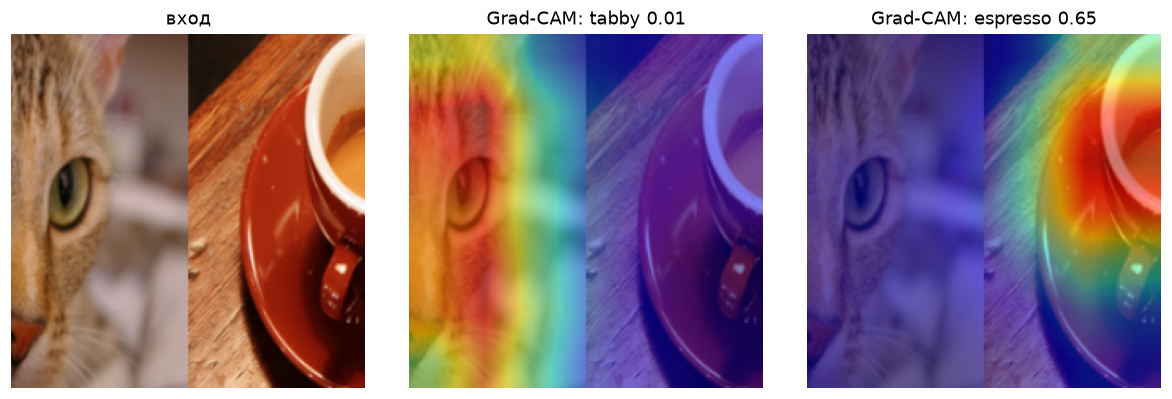

In [3]:
comp = np.concatenate([np.asarray(Image.fromarray(data.chelsea()).resize((224, 224))),
                       np.asarray(Image.fromarray(data.coffee()).resize((224, 224)))], 1)
XR = tf(Image.fromarray(comp))[None]; pr = logits(XR).softmax(-1)[0]
c1 = max([281, 282, 283, 284, 285], key=lambda k: float(pr[k])); c2 = max([967, 968, 504], key=lambda k: float(pr[k]))
g1, g2 = gradcam(XR, c1), gradcam(XR, c2)
print(f"{CATS[c1]} p = {float(pr[c1]):.3f};  {CATS[c2]} p = {float(pr[c2]):.3f}")
print(f"доля карты {CATS[c1]} слева: {g1[:, :112].sum() / g1.sum():.2f};  доля карты {CATS[c2]} справа: {g2[:, 112:].sum() / g2.sum():.2f}")
print(f"Spearman двух карт: {spearmanr(g1.ravel(), g2.ravel())[0]:.2f}")
XK = tf(Image.fromarray(data.rocket()))[None]; tk = logits(XK).softmax(-1)[0].topk(2)
h1, h2 = gradcam(XK, int(tk.indices[0])), gradcam(XK, int(tk.indices[1]))
print(f"ракета: {CATS[int(tk.indices[0])]} {float(tk.values[0]):.2f}, {CATS[int(tk.indices[1])]} {float(tk.values[1]):.2f};  Spearman карт {spearmanr(h1.ravel(), h2.ravel())[0]:.2f}")
fig, axs = plt.subplots(1, 3, figsize=(11, 3.6))
axs[0].imshow(show(XR[0])); axs[0].set_title("вход")
for ax, gm, c in [(axs[1], g1, c1), (axs[2], g2, c2)]:
    ax.imshow(show(XR[0])); ax.imshow(gm / gm.max(), cmap="jet", alpha=0.5); ax.set_title(f"Grad-CAM: {CATS[c]} {float(pr[c]):.2f}")
for ax in axs: ax.axis("off")
plt.tight_layout(); plt.show()

**В чём измеряется.** Доля суммы карты в половине картинки (от 0 до 1); Spearman — от −1 до 1.

### На что обращать внимание

- **Класс, который модель почти не выбирает, тоже объясним.** У tabby вероятность 0,01, но его карта на 92 % лежит на кошке. Карта отвечает «что в картинке говорит за названный класс», а не «почему модель ответила так».
- **Соседние классы — одна карта.** На ракете у двух топ-классов Spearman карт 0,81: где объект — видно, почему этот класс — нет.

## 1.3. Почему последний свёрточный слой — эвристика

### Блок «Теория»

Grad-CAM классически берут с последнего свёрточного слоя (`layer4` у ResNet). Это эвристика, а не теорема.

- **За:** признаки там самые семантические, а между слоем и логитом — только pooling и линейный слой, поэтому средний градиент по каналу честно отражает вклад канала в класс; на ResNet это ровно CAM.
- **Цена:** разрешение 7 × 7.

Нюансы метода:

- **ReLU прячет «против».** Клетки, которые понижают логит класса, на карте не видны.
- **Нормировка прячет масштаб.** После деления на максимум по карте не понять, насколько модель уверена: у tabby (p = 0,01) карта выглядит так же ярко, как у espresso (p = 0,65).
- **Класс надо называть** (1.2).

Как карты проверяют — sanity checks и deletion — на занятии 08.

### Как устроен код
```
Grad-CAM без ReLU (7×7): кошка одна и кошачий класс на картинке «кошка | кофе»
число отрицательных клеток, в какой они половине, их сумма против суммы положительных
```

In [4]:
for name, x, c in [("кошка", XC, cC), ("кошка | кофе", XR, c1)]:
    m = gc.attribute(x.clone().requires_grad_(True), target=c, relu_attributions=False)[0, 0].detach()
    neg = m < 0; right = torch.zeros_like(neg); right[:, m.shape[1] // 2 + 1:] = True
    print(f"{name:13s} {CATS[c]}: отрицательных клеток {int(neg.sum())} из {m.numel()}, из них в правой половине {int((neg & right).sum())};  "
          f"сумма отрицательных {float(m[neg].sum()):+.2f}, положительных {float(m[~neg].sum()):+.2f}")

кошка         tiger cat: отрицательных клеток 0 из 49, из них в правой половине 0;  сумма отрицательных +0.00, положительных +15.56
кошка | кофе  tabby: отрицательных клеток 6 из 49, из них в правой половине 6;  сумма отрицательных -0.12, положительных +10.53


**В чём измеряется.** Число клеток 7×7 и сумма значений Grad-CAM (единицы логита / 49).

### На что обращать внимание

- Отрицательные клетки — свидетельства против класса. После ReLU они обнуляются, и карта показывает только «за».
- **Здесь «против» слабое.** На одной кошке отрицательных клеток нет вовсе; на склейке они есть только на стороне кофе, и их сумма в десятки раз меньше суммы «за». Так бывает не всегда: у классов-соседей «против» может быть заметным, и ReLU его спрячет.

---
# Часть 2. Трансформер: внимание

## 2.1. Attention rollout

### Блок «Теория»

Вес внимания $A_{ij}$ — сколько токен $i$ берёт от токена $j$ в одном слое. С занятия 05: вес ≠ вклад, в выход входит $A_{ij}\cdot v_j W_O$ (Kobayashi et al., 2020), а после слоя ещё residual, MLP и следующие слои.

**Attention rollout** (Abnar & Zuidema, 2020) собирает внимание всех слоёв. В каждом слое берём среднее внимание по головам, добавляем единичную матрицу (это residual), нормируем строки и перемножаем:
$$\tilde A_l = \tfrac12 A_l + \tfrac12 I, \qquad R = \tilde A_L \cdots \tilde A_1, \qquad \text{важность патча } j = R[\mathrm{CLS}, j].$$

По рамке: единица — патч, процесс — произведение матриц внимания, baseline нет, **цели нет**.

**Пример.** ViT-tiny (12 слоёв, 3 головы, 196 патчей 16×16 и токен [CLS]) смотрит на кошку. Куда «смотрит» [CLS] последнего слоя и куда — через все слои?

### Как устроен код
```
внимание ← ViT(картинка, output_attentions)          # 12 × [головы, 197, 197]
последний ← среднее по головам внимание [CLS] → патчи, слой 12
R ← I; для каждого слоя: Ã ← ½A + ½I, нормировать строки, R ← Ã · R
rollout ← R[CLS, патчи]
```

ViT-tiny, топ-2: [('Egyptian cat', 0.739), ('tiger cat', 0.142)]
слоёв: 12  форма внимания слоя: (1, 3, 197, 197)
Spearman(rollout, последний слой) = 0.44


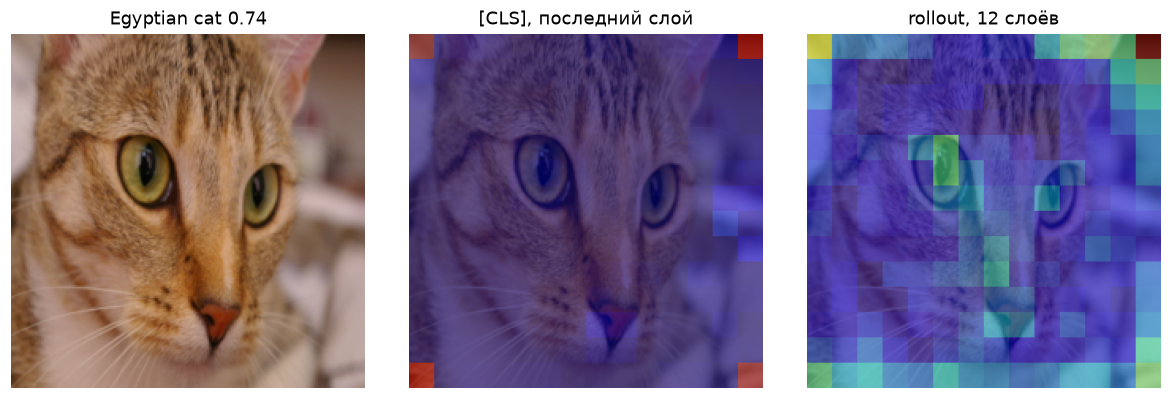

In [5]:
VIT = "WinKawaks/vit-tiny-patch16-224"
vproc = ViTImageProcessor.from_pretrained(VIT); vit = ViTForImageClassification.from_pretrained(VIT, attn_implementation="eager").eval()
for p in vit.parameters(): p.requires_grad_(False)
XV = vproc(images=Image.fromarray(data.chelsea()), return_tensors="pt").pixel_values
with torch.no_grad(): out = vit(pixel_values=XV, output_attentions=True)
pv = out.logits.softmax(-1)[0]; cV, cV2 = [int(i) for i in pv.topk(2).indices]
print("ViT-tiny, топ-2:", [(vit.config.id2label[c], round(float(pv[c]), 3)) for c in (cV, cV2)])
print("слоёв:", len(out.attentions), " форма внимания слоя:", tuple(out.attentions[0].shape))

att = [a[0].mean(0) for a in out.attentions]                          # среднее по головам, [197, 197]
last = att[-1][0, 1:].reshape(14, 14).numpy()
R = torch.eye(197)
for a in att:
    a_ = 0.5 * a + 0.5 * torch.eye(197); a_ = a_ / a_.sum(-1, keepdim=True); R = a_ @ R
roll = R[0, 1:].reshape(14, 14).numpy()
print(f"Spearman(rollout, последний слой) = {spearmanr(roll.ravel(), last.ravel())[0]:.2f}")
IMGV = (XV[0] * 0.5 + 0.5).permute(1, 2, 0).clamp(0, 1).numpy()
def up(m): return np.kron(m, np.ones((16, 16)))
fig, axs = plt.subplots(1, 3, figsize=(11, 3.6))
axs[0].imshow(IMGV); axs[0].set_title(f"{vit.config.id2label[cV]} {float(pv[cV]):.2f}")
for ax, m, t in [(axs[1], last, "[CLS], последний слой"), (axs[2], roll, "rollout, 12 слоёв")]:
    ax.imshow(IMGV); ax.imshow(up(m / m.max()), cmap="jet", alpha=0.5); ax.set_title(t)
for ax in axs: ax.axis("off")
plt.tight_layout(); plt.show()

**В чём измеряется.** Доля внимания (строки матриц внимания суммируются в 1); у rollout — доля «потока внимания», дошедшая от патча до [CLS].

### На что обращать внимание

- **Последний слой смотрит в фон.** У этой модели внимание [CLS] последнего слоя почти всё в угловых патчах фона, а не на кошке. У больших ViT похожие артефакты — токены с большой нормой в малоинформативных патчах фона — описаны в Darcet et al. (2024).
- **Rollout шире и другой:** со вниманием последнего слоя Spearman 0,44.
- **Residual — решение автора.** Коэффициенты ½ и ½ — допущение rollout о том, сколько информации идёт через residual.

## 2.2. Внимание против вмешательства; внимание не привязано к классу

### Блок «Теория»

Проверим внимание вмешательством — окклюзией с занятия 06: закрываем по очереди каждый патч 16×16 размытой версией и смотрим, насколько падает вероятность класса. Внимание отвечает «куда смотрела модель при вычислении», окклюзия — «без чего изменился бы ответ». Это разные вопросы (спор Jain & Wallace, 2019, и Wiegreffe & Pinter, 2019).

У rollout нет цели: карта одна для любого класса. Окклюзия — про конкретный класс. Класс-специфичные карты трансформера комбинируют внимание с градиентом (например, Chefer et al., 2021).

### Как устроен код
```
pvnet ← ViT + softmax                                  # цель — вероятность класса
окклюзия ← captum.Occlusion(окно 16×16 = патч, шаг 16, baseline — размытая картинка)
для двух топ-классов: карта окклюзии 14×14
Spearman: rollout ~ окклюзия, последний слой ~ окклюзия, окклюзия класс 1 ~ класс 2
```

Spearman с окклюзией (Egyptian cat): rollout 0.12, последний слой -0.03
окклюзия Egyptian cat ~ tiger cat: -0.83;  rollout для обоих классов один


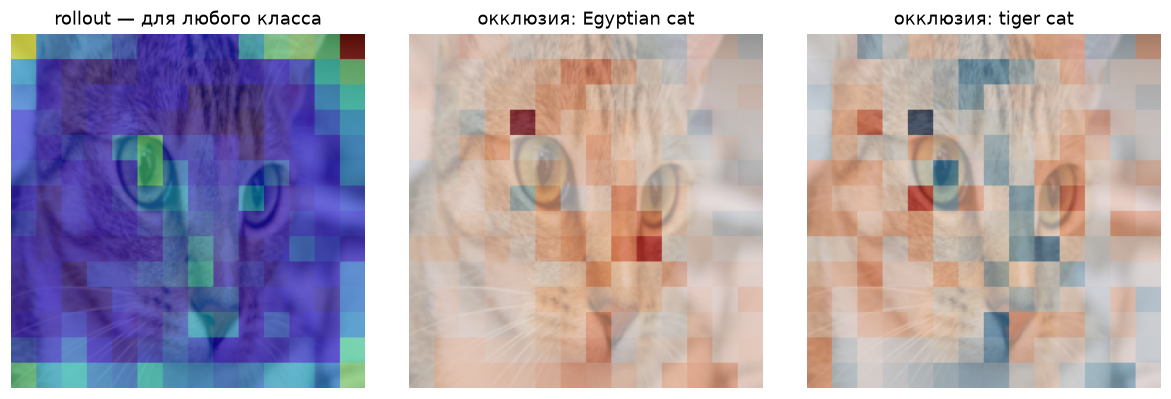

In [6]:
class ProbV(nn.Module):
    def forward(self, x): return vit(pixel_values=x).logits.softmax(-1)
pvnet = ProbV().eval(); XVB = GaussianBlur(51, sigma=20)(XV)
def occ_vit(c):
    a = Occlusion(pvnet).attribute(XV, sliding_window_shapes=(3, 16, 16), strides=(3, 16, 16), target=c, baselines=XVB)
    return a[0].sum(0).numpy()[::16, ::16] / 3                        # одно значение на патч
o1, o2 = occ_vit(cV), occ_vit(cV2)
print(f"Spearman с окклюзией ({vit.config.id2label[cV]}): rollout {spearmanr(roll.ravel(), o1.ravel())[0]:.2f}, "
      f"последний слой {spearmanr(last.ravel(), o1.ravel())[0]:.2f}")
print(f"окклюзия {vit.config.id2label[cV]} ~ {vit.config.id2label[cV2]}: {spearmanr(o1.ravel(), o2.ravel())[0]:.2f};  rollout для обоих классов один")
fig, axs = plt.subplots(1, 3, figsize=(11, 3.6))
axs[0].imshow(IMGV); axs[0].imshow(up(roll / roll.max()), cmap="jet", alpha=0.5); axs[0].set_title("rollout — для любого класса")
for ax, o, c in [(axs[1], o1, cV), (axs[2], o2, cV2)]:
    vm = np.abs(o).max(); ax.imshow(IMGV); ax.imshow(up(o), cmap="RdBu_r", vmin=-vm, vmax=vm, alpha=0.6)
    ax.set_title(f"окклюзия: {vit.config.id2label[c].split(',')[0]}")
for ax in axs: ax.axis("off")
plt.tight_layout(); plt.show()

**В чём измеряется.** Окклюзия — падение вероятности класса при закрытии патча (красный — патч за класс, синий — против); Spearman — от −1 до 1.

### На что обращать внимание

- **Внимание слабо согласуется с вмешательством:** rollout 0,12, последний слой около нуля.
- **Классы различаются знаком на тех же патчах.** Окклюзия для Egyptian cat и tiger cat — Spearman −0,83: что говорит за один класс, говорит против другого. Внимание этого не видит.
- Хорошая практика: внимание подсказывает гипотезу, вмешательство её проверяет.

---
# Часть 3. Графовая сеть: какие рёбра объясняют прогноз

## 3.1. Передача сообщений и граф Tree-Cycles

### Блок «Теория»

Графовая свёрточная сеть (Kipf & Welling, 2017) на каждом слое усредняет представления соседей:
$$H^{(l+1)} = \sigma\big(\hat A H^{(l)} W^{(l)}\big), \qquad \hat A = D^{-1/2}(A + I)D^{-1/2}.$$
После $k$ слоёв узел «видит» только свою $k$-окрестность — поэтому объяснение прогноза для узла живёт в ней: какие рёбра повлияли.

**Tree-Cycles** (Ying et al., 2019): бинарное дерево из 511 узлов, к которому прикреплены 80 циклов по 6 узлов. Метка узла — в цикле он или в дереве. Признаков у узлов нет (все единицы), различать можно только по структуре. Рёбра циклов — «истина по построению».

Чтобы объяснять рёбра, у каждого ребра есть вес $w_e$ (по умолчанию 1), и сеть дифференцируема по нему.

### Как устроен код
```
G ← бинарное дерево глубины 8 + 80 циклов по 6, каждый прикреплён одним ребром к случайному узлу дерева
GCN: 3 слоя, плотная матрица смежности, собранная из весов рёбер w
обучить 600 эпох на 80 % узлов; точность на обучении и тесте
```

In [7]:
def tree_cycles(depth=8, n_cycles=80, seed=0):
    rg = np.random.default_rng(seed)
    G = nx.balanced_tree(2, depth); nb = G.number_of_nodes(); lab = [0] * nb; motif = set()
    for _ in range(n_cycles):
        s = G.number_of_nodes(); cyc = [(s + i, s + (i + 1) % 6) for i in range(6)]
        G.add_nodes_from(range(s, s + 6)); G.add_edges_from(cyc); motif |= {tuple(sorted(e)) for e in cyc}; lab += [1] * 6
        G.add_edge(int(rg.integers(nb)), s)
    return G, np.array(lab), motif
G, Y, MOTIF = tree_cycles()
NN_ = G.number_of_nodes(); EDGES = np.array([tuple(sorted(e)) for e in G.edges()]); EI = torch.tensor(EDGES.T)
IS_M = np.array([tuple(e) in MOTIF for e in EDGES]); XG = torch.ones(NN_, 1)

class GCN(nn.Module):
    def __init__(s, h=32, c=2):
        super().__init__(); s.layers = nn.ModuleList([nn.Linear(1, h), nn.Linear(h, h), nn.Linear(h, h)]); s.out = nn.Linear(3 * h, c)
    def forward(s, x, w=None):                                         # w — веса рёбер
        w = torch.ones(EI.shape[1]) if w is None else w
        Aj = torch.zeros(NN_, NN_).index_put((EI[0], EI[1]), w, accumulate=True).index_put((EI[1], EI[0]), w, accumulate=True) + torch.eye(NN_)
        d = Aj.sum(1).pow(-0.5); Aj = d[:, None] * Aj * d[None]; hs = []
        for l in s.layers: x = F.relu(l(Aj @ x)); hs.append(x)
        return s.out(torch.cat(hs, 1))

torch.manual_seed(0); gcn = GCN(); yt = torch.tensor(Y)
perm = np.random.default_rng(0).permutation(NN_); tr, te = torch.tensor(perm[:int(.8 * NN_)]), torch.tensor(perm[int(.8 * NN_):])
opt = torch.optim.Adam(gcn.parameters(), lr=0.01, weight_decay=5e-4)
for _ in range(600):
    loss = F.cross_entropy(gcn(XG)[tr], yt[tr]); opt.zero_grad(); loss.backward(); opt.step()
gcn.eval()
for p in gcn.parameters(): p.requires_grad_(False)
with torch.no_grad(): PRED = gcn(XG).argmax(1)
print(f"узлов {NN_}, рёбер {len(EDGES)}, из них в циклах {IS_M.sum()}")
print(f"точность: обучение {(PRED[tr] == yt[tr]).float().mean():.2f}, тест {(PRED[te] == yt[te]).float().mean():.2f}")

узлов 991, рёбер 1070, из них в циклах 480
точность: обучение 0.97, тест 0.93


**В чём измеряется.** Доля верно классифицированных узлов.

### На что обращать внимание

- **Окрестность ограничена числом слоёв.** Трёхслойная сеть не видит дальше трёх рёбер; узел цикла «видит» весь свой цикл (до противоположного узла — 3 ребра) и кусок дерева.

## 3.2. Ребро как единица: градиент и удаление

### Блок «Теория»

Для узла $v$ и класса «цикл» объясним рёбра его 3-окрестности двумя процессами с занятия 06:

- **градиент** по весу ребра: $\big|\partial f_c(v) / \partial w_e\big|$ при $w = 1$;
- **вмешательство** — удаление ребра: $f_c(v) - f_c(v \mid w_e = 0)$. Baseline — «ребра нет».

**GNNExplainer** (Ying et al., 2019) — третий процесс: вместо того чтобы удалять рёбра по одному, он **оптимизирует** мягкую маску $M_e\in[0,1]$ на всех рёбрах окрестности сразу:
$$\min_M\; -\log p_c\big(v \mid M\odot A\big) + \lambda_{size}\sum_e M_e + \lambda_{ent}\,H(M).$$
Первый член сохраняет прогноз, второй штрафует размер маски, третий — энтропию весов. По рамке: единица — ребро, процесс — вмешательство, найденное оптимизатором, baseline — вес 0, цель — $\log p$ класса узла. Реализацию вы напишете в ДЗ-2, поэтому здесь её нет.

**Пример.** Узел цикла, прикреплённый к дереву: какие рёбра окрестности важны для «цикл»?

### Как устроен код
```
v ← первый узел цикла, прикреплённый к дереву (верно классифицирован)
окрестность ← рёбра, оба конца которых в 3-окрестности v
градиент ← |∂ logit_цикл(v) / ∂ w| при w = 1
удаление ← для каждого ребра окрестности: logit(v) − logit(v | w_e = 0)
сравнить с рёбрами цикла: средние значения, Spearman двух атрибуций
```

узел 511: рёбер в 3-окрестности 11, из них в цикле 6
|градиент| : среднее на рёбрах цикла +0.618, на остальных +0.672
удаление   : среднее на рёбрах цикла +1.035, на остальных -0.624
Spearman(|градиент|, удаление) по рёбрам окрестности: -0.90


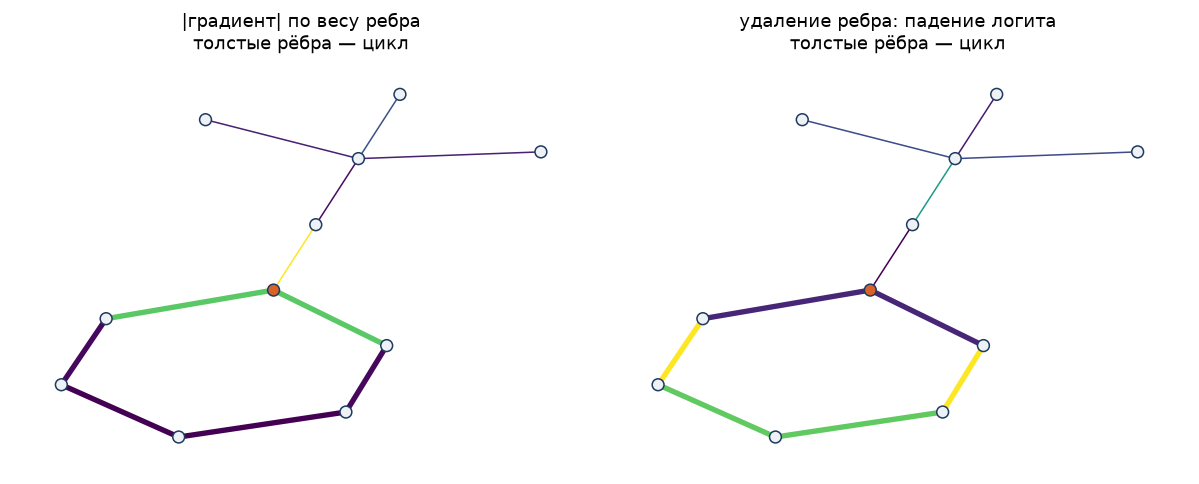

In [8]:
v = next(n for n in range(511, NN_, 6) if PRED[n] == 1)            # узел цикла, прикреплённый к дереву
near = set(nx.single_source_shortest_path_length(G, v, cutoff=3))
sub = np.array([a in near and b in near for a, b in EDGES]); idx = np.where(sub)[0]
w = torch.ones(EI.shape[1], requires_grad=True); gcn(XG, w)[v, 1].backward(); grad = w.grad.abs().numpy()
base = float(gcn(XG)[v, 1]); dele = np.zeros(len(EDGES))
for e in idx:
    w0 = torch.ones(EI.shape[1]); w0[e] = 0; dele[e] = base - float(gcn(XG, w0)[v, 1])
print(f"узел {v}: рёбер в 3-окрестности {len(idx)}, из них в цикле {IS_M[idx].sum()}")
for name, a in [("|градиент|", grad), ("удаление", dele)]:
    print(f"{name:11s}: среднее на рёбрах цикла {a[sub & IS_M].mean():+.3f}, на остальных {a[sub & ~IS_M].mean():+.3f}")
print(f"Spearman(|градиент|, удаление) по рёбрам окрестности: {spearmanr(grad[idx], dele[idx])[0]:.2f}")

H = nx.Graph(); H.add_edges_from(EDGES[idx]); pos = nx.kamada_kawai_layout(H)
fig, axs = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, a, t in [(axs[0], grad, "|градиент| по весу ребра"), (axs[1], dele, "удаление ребра: падение логита")]:
    nx.draw_networkx_edges(H, pos, ax=ax, edgelist=[tuple(e) for e in EDGES[idx]], edge_color=a[idx], edge_cmap=plt.cm.viridis,
                           width=[3.5 if m else 1.0 for m in IS_M[idx]])
    nx.draw_networkx_nodes(H, pos, ax=ax, node_size=60, node_color=["#D9622B" if n == v else "#EEF2F7" for n in H.nodes()], edgecolors="#1F3A5F")
    ax.set_title(t + "\nтолстые рёбра — цикл"); ax.axis("off")
plt.tight_layout(); plt.show()

**В чём измеряется.** Градиент — единицы логита на единицу веса ребра; удаление — падение логита класса «цикл».

### На что обращать внимание

- **Градиент и удаление отвечают на разные вопросы**, как на занятии 06: бесконечно малое изменение веса против «ребра нет». Здесь они почти противоположны: Spearman −0,90. Удаление ставит рёбра цикла выше (в среднем +1,04 против −0,62), модуль градиента — нет (0,62 против 0,67).
- **Отрицательный вклад удаления.** Удаление ребра дерева *повышает* логит «цикла»: без него окрестность узла меньше похожа на дерево. Модуль градиента знак теряет.
- **Истина по построению ≠ то, на что опирается модель.** Рёбра цикла мы заложили сами; но признаков у узлов нет, и модель может различать узлы по локальной структуре степеней, включая рёбра дерева. На занятии мы видели: на 12 таких узлах средний ROC-AUC против рёбер цикла у GNNExplainer 0,52 (от 0,12 до 1,00), у градиента 0,36. Как проверять объяснение, когда истина неизвестна или не совпадает с механизмом модели, — занятие 08.

---
# Часть 4. Мультимодальность: CLIP

## 4.1. Общее пространство и zero-shot

### Блок «Теория»

CLIP (Radford et al., 2021) учит кодировщик картинок $e(x)$ и кодировщик текста $e(t)$ так, чтобы эмбеддинги подходящей пары были близки по косинусу. Классификация «с нуля» — softmax по набору подписей:
$$\cos(x,t) = \frac{\langle e(x), e(t)\rangle}{\|e(x)\|\,\|e(t)\|}, \qquad p(t\mid x) = \mathrm{softmax}_t\big(100\cdot\cos(x,t)\big).$$

Выход модели — сходство, а не логит класса. Поэтому четвёртый пункт рамки, цель, архитектурой не задан: можно объяснять сырой косинус с одной подписью, вероятность подписи среди набора или место в выдаче. Это разные вопросы; какой из них даёт карту, различающую подписи, вы проверите в ДЗ-2.

### Как устроен код
```
эмбеддинги картинки с кофе и пяти подписей, нормированные
cos ← скалярные произведения; p ← softmax(100 · cos)
```

In [9]:
CL = "openai/clip-vit-base-patch32"
clip = CLIPModel.from_pretrained(CL).eval(); cp = CLIPProcessor.from_pretrained(CL)
def _e(o): o = o if torch.is_tensor(o) else o.pooler_output; return o / o.norm(dim=-1, keepdim=True)
@torch.no_grad()
def temb(t): return _e(clip.get_text_features(**cp(text=t, return_tensors="pt", padding=True)))
@torch.no_grad()
def iemb(im): return _e(clip.get_image_features(pixel_values=cp(images=[im], return_tensors="pt").pixel_values))
COF, CAT = Image.fromarray(data.coffee()), Image.fromarray(data.chelsea())
PR = ["a photo of a cup of coffee", "a photo of a saucer", "a photo of a spoon", "a photo of a cat", "a photo of a rocket"]
cos = (iemb(COF) @ temb(PR).T)[0]; prb = torch.softmax(100 * cos, -1)
for p_, c_, q_ in zip(PR, cos, prb): print(f"{p_:30s} cos {float(c_):.3f}   p {float(q_):.3f}")

a photo of a cup of coffee     cos 0.302   p 0.973
a photo of a saucer            cos 0.266   p 0.026
a photo of a spoon             cos 0.226   p 0.000
a photo of a cat               cos 0.201   p 0.000
a photo of a rocket            cos 0.182   p 0.000


**В чём измеряется.** Косинус — от −1 до 1; вероятность — доля среди пяти подписей.

### На что обращать внимание

- **Косинусы близки, вероятности — нет.** Все пять подписей — от 0,18 до 0,30, а вероятность верной — 0,97: множитель 100 и softmax растягивают малые разницы. Объяснять косинус и объяснять вероятность — разные вопросы.

## 4.2. Текстовая сторона: какие слова отвечают за сходство

### Блок «Теория»

Leave-one-out по словам подписи (занятие 06): вклад слова — падение косинуса подписи с картинкой, если слово удалить. По рамке: единица — слово, процесс — удаление, цель — косинус.

**Пример.** Подпись «a cup of espresso with a spoon on a white saucer» сравниваем с картинкой кофе и с картинкой кошки. Если слово работает на конкретную картинку, падение будет только для кофе.

### Как устроен код
```
для каждого слова k: подпись без слова k
вклад_k ← cos(подпись, картинка) − cos(подпись без k, картинка)
для картинки кофе и картинки кошки
```

cos с кофе 0.308, с кошкой 0.188


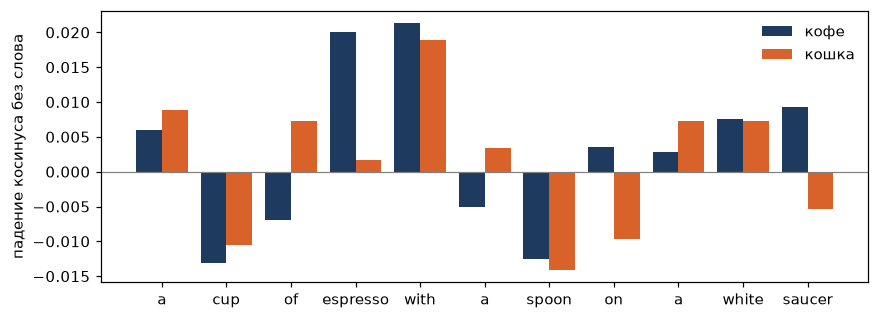

In [10]:
CAP = "a cup of espresso with a spoon on a white saucer"
def word_loo(caption, ie):
    ws = caption.split(); base = float(temb([caption]) @ ie.T)
    sims = (temb([" ".join(ws[:k] + ws[k + 1:]) for k in range(len(ws))]) @ ie.T)[:, 0].numpy()
    return ws, base, base - sims
ws, b1, d1 = word_loo(CAP, iemb(COF)); _, b2, d2 = word_loo(CAP, iemb(CAT))
print(f"cos с кофе {b1:.3f}, с кошкой {b2:.3f}")
xx = np.arange(len(ws)); plt.figure(figsize=(9, 3.2))
plt.bar(xx - 0.2, d1, 0.4, color="#1F3A5F", label="кофе"); plt.bar(xx + 0.2, d2, 0.4, color="#D9622B", label="кошка")
plt.axhline(0, color="gray", lw=0.8); plt.xticks(xx, ws); plt.ylabel("падение косинуса без слова"); plt.legend(frameon=False); plt.show()

**В чём измеряется.** Падение косинуса, сотые доли.

### На что обращать внимание

- **Слово про картинку и слово про любую картинку.** espresso: падение 0,020 с кофе и 0,002 с кошкой; служебное with — 0,021 и 0,019. Сравнение с другой картинкой отделяет одно от другого — та же идея «цели относительно других», что и с подписями в 4.1.
- **Отрицательный вклад.** Без cup и spoon подпись ближе к картинке: удаление слова меняет и смысл, и длину текста.
- **Эффекты маленькие** и отвечают на вопрос о сходстве текста с картинкой, а не «что на картинке».

## 4.3. VLM обзорно: смотрит ли модель на картинку

Модели «картинка + текст → текст» объясняют теми же средствами: атрибуция ответа к патчам и к токенам вопроса. Главный вопрос — опирается ли ответ на картинку. На многие вопросы VQA можно ответить по одному тексту вопроса; датасет VQA v2 составили из пар похожих картинок с разными ответами на один вопрос (Goyal et al., 2017). Проверка — вмешательство в картинку: заменить, затемнить, подставить другую. Если ответ не меняется — модель ответила по тексту.

---
# Итог

| Архитектура | Даёт | Метод | Чего не даёт |
|---|---|---|---|
| свёрточная сеть | карты признаков 7×7 | Grad-CAM (= CAM на ResNet) | деталей; свидетельств «против»; класс называют |
| трансформер | веса внимания | attention rollout | вклада; привязки к классу; согласия с вмешательством |
| графовая сеть | k-окрестность, рёбра | градиент, удаление, GNNExplainer | гарантии, что объяснение = механизм модели |
| мультимодальная | общее пространство | удаление слова, окклюзия | готовой цели: её выбирают |

Устройство модели подсказывает гипотезу, вмешательство во вход её проверяет. Как проверять сами объяснения — занятие 08.

## Литература
- Zhou et al. Learning deep features for discriminative localization. CVPR 2016.
- Selvaraju et al. Grad-CAM: visual explanations from deep networks via gradient-based localization. ICCV 2017.
- Kobayashi et al. Attention is not only a weight. EMNLP 2020.
- Abnar & Zuidema. Quantifying attention flow in transformers. ACL 2020.
- Jain & Wallace. Attention is not explanation. NAACL 2019. Wiegreffe & Pinter. Attention is not not explanation. EMNLP 2019.
- Chefer, Gur, Wolf. Transformer interpretability beyond attention visualization. CVPR 2021.
- Darcet, Oquab, Mairal, Bojanowski. Vision transformers need registers. ICLR 2024.
- Kipf & Welling. Semi-supervised classification with graph convolutional networks. ICLR 2017.
- Ying et al. GNNExplainer: generating explanations for graph neural networks. NeurIPS 2019.
- Radford et al. Learning transferable visual models from natural language supervision. ICML 2021.
- Goyal et al. Making the V in VQA matter. CVPR 2017.